# JupyerLab notebook example for Pulse Structure investigations

/!\ /!\ /!\  
Oxygen diffusion from cell environment not (yet) included in the model.  
Therefore, the oxygen level is reinitialized before each new pulse.  

## Module imports

In [1]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Modules from Standard lib
from pathlib import Path
import typing as tp

# RadioBio module
import radiopyo as rp
from radiopyo.simulation.utils import ResCollection

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

## Simulation Run

**1) Load configuration from the toml file +**  
 -> create a ref to O2 species for later use  
 -> define the desired number of pulses  
 -> define the period

In [3]:
file = Path(rf"configuration_ELBE.toml")
uc = rp.UnitCell.from_toml(file)

2023-07-31 10:16:44,775::radiopyo::INFO::Loading config from file: configuration_ELBE.toml
2023-07-31 10:16:44,783::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\config_Labarbe.toml
2023-07-31 10:16:44,785::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\basic_water_radiolysis.toml
2023-07-31 10:16:45,023::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\reactions_biology.toml
2023-07-31 10:16:45,063::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2023-07-31 10:16:45,304::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2023-07-31 10:16:45,498::radiopyo::INFO::File is loaded
2023-07-31 10:16:45,499::radiopyo::INFO::Beam configuration detected in config file
2023-07-31 10:16:45,500::radiopyo::INFO::BEAM:: Assigning 'default' name to beam definition constant -> {'dose_rate': 0.13, 'max_dose': 32, 's

## Simulation Run LOOP

In [8]:
rp.set_logging_level("ERROR")

In [56]:
uc.beam_list.current

ConstantBeam(dose_rate=110000.0, timer=Timer(period=inf, on_time=inf, start_time=0.0), max_dose=32, label='default', time_at_max_dose=0.0002909090909090909, dose_per_pulse=inf, peak_dose_rate=110000.0)

In [51]:
sims = ResCollection("Dose Rate [Gy/s]")
for adr in [0.13, 1, 10, 150, 201.9, 319, 1e3, 1e4, 1.1e5]:
    uc.beam_list.current.update_beam_param(dose_rate=adr)
    sim = uc.prepare_chunked_run([1e-9, 600], atol=1e-1, rtol=1e-2, use_jac=False)
    sims.push(adr, sim.run())



2023-07-31 11:03:54,487::radiopyo::INFO::Simulation divided in 2 chunks
2023-07-31 11:03:54,489::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-07-31 11:03:54,633::radiopyo::INFO::Simulation done!
2023-07-31 11:03:54,634::radiopyo::INFO::Simulation divided in 2 chunks
2023-07-31 11:03:54,636::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-07-31 11:03:54,749::radiopyo::INFO::Simulation done!
2023-07-31 11:03:54,749::radiopyo::INFO::Simulation divided in 2 chunks
2023-07-31 11:03:54,752::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

... (9 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

2023-07-31 11:04:03,580::radiopyo::INFO::Simulation done!
2023-07-31 11:04:03,581::radiopyo::INFO::Simulation divided in 2 chunks
2023-07-31 11:04:03,584::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-07-31 11:04:07,450::radiopyo::INFO::Simulation done!


In [56]:
bins = np.arange(start=0, stop=df.index[-1], step=1e-3)
df.groupby(pd.cut(df["KR_7"], bins=bins)).

## Results usage

### Plot

In [52]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1e3

def make_basic_plot(fig:plt.Figure,
                    ax:plt.Axes,
                    species:str,
                    rescoll:ResCollection,
                    title:str="",
                    xscale:str="log",
                    yscale:str="log",
                    ylim:tp.Tuple[float, float]=(1e-6, 10),
                    xlim:tp.Tuple[float, float]=(1e-6, RIGHT_LIMIT),
                    legend:bool=True,
                   ):
    for label, df in rescoll.iter_pandas():
        ax.plot(df.index, df[species], label=label, marker="")

    ax.set_ylim(ylim)
    ax.set_xlim(xlim)
    ax.set_xscale(xscale)
    ax.set_yscale(yscale)
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.set_title(title)
    if legend:
        ax.legend(fancybox=True, framealpha=1)
    

#### Water-only Radiolytic produced species

In [53]:
fig_man.set_brewer_map("RdYlGn", "diverging", 9, reverse=True)

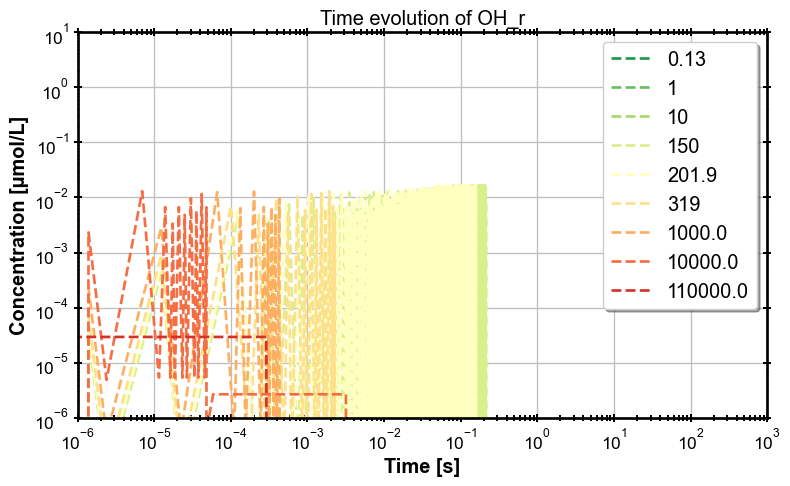

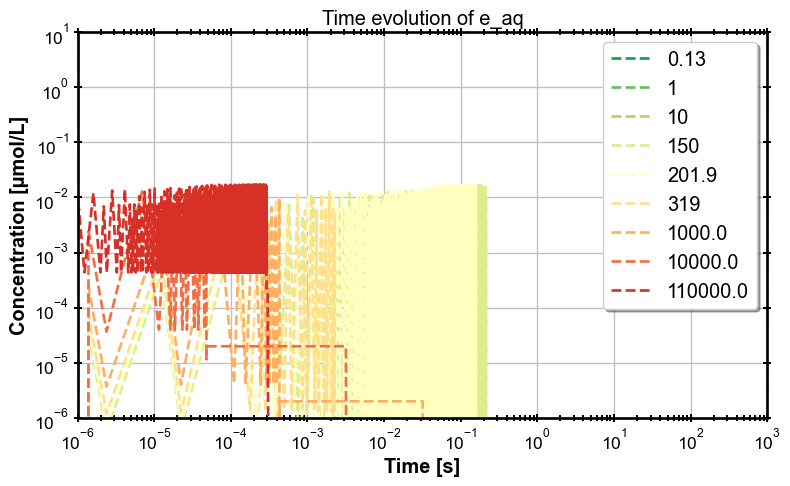

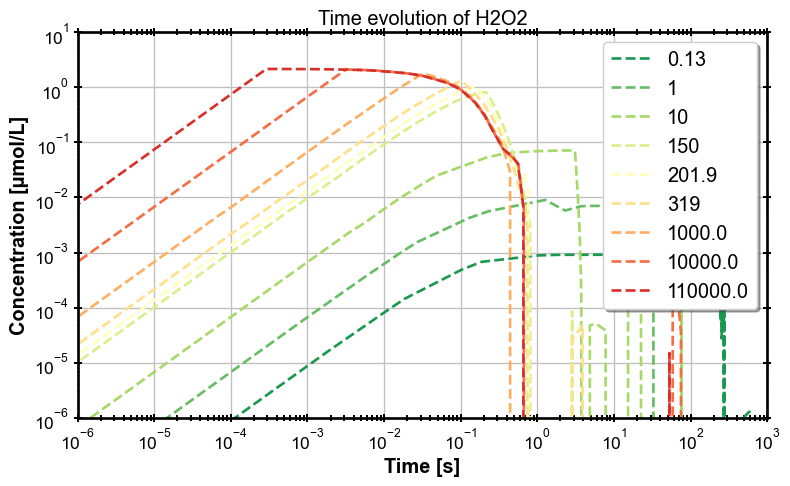

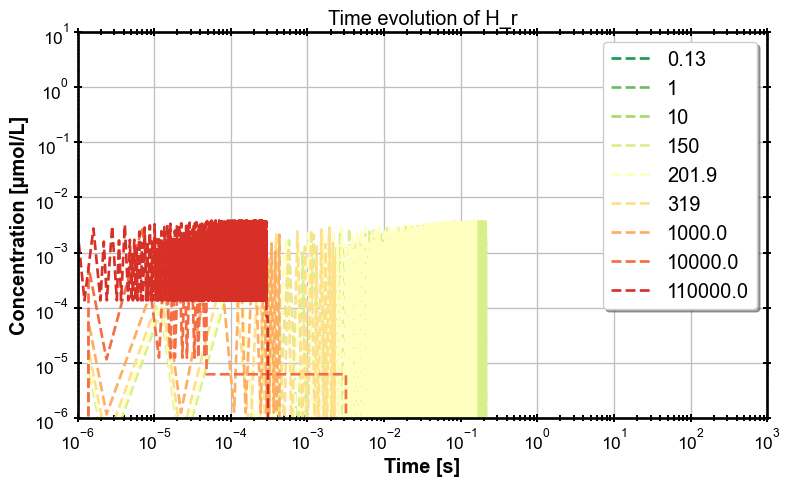

In [54]:
G_species = ["OH_r", "e_aq", "H2O2", "H_r"]
for species in G_species:
    title = f"Time evolution of {species}"
    with fig_man.open(title) as (fig, ax):
        make_basic_plot(fig, ax, species, sims, title)

#### Biology related species

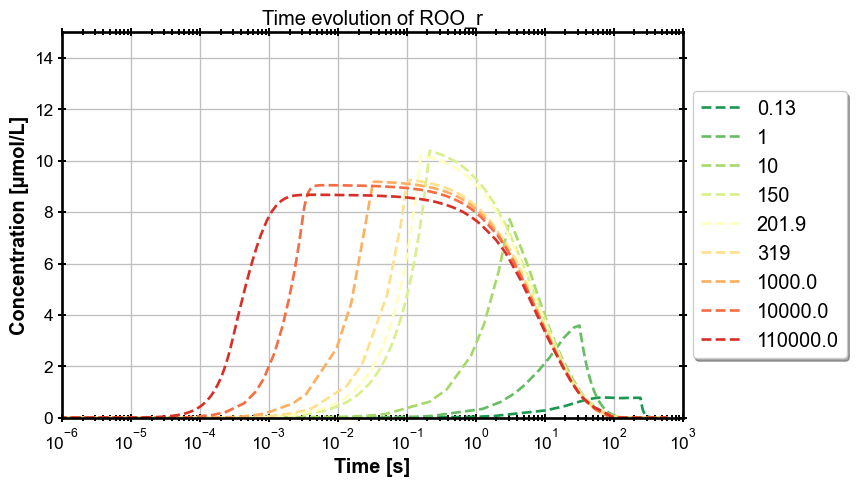

In [58]:
species = "ROO_r"
title = f"Time evolution of {species}"
with fig_man.open(title) as (fig, ax):
    make_basic_plot(fig, ax, species, sims, title, legend=False, yscale="linear", ylim=[0,15])
    RPlot.set_legend_right(ax)

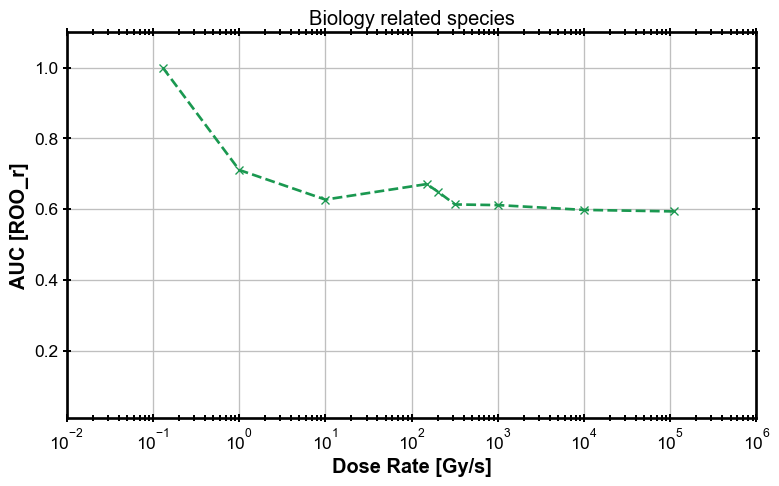

In [59]:
species = "ROO_r"
adf = pd.Series(dtype=np.float64)
for adr, df in sims.iter_pandas():
    mask = np.where((df.index>=1e-6))
    adf.loc[adr] = simpson(y=df[species].values[mask].clip(min=0), x=df.index[mask])
    
with fig_man.open(f"Comparison of {species} ROO_r") as (fig, ax):
    
    ax.plot(adf.index, adf/adf.max(), marker="x")

    #ax.set_ylim(bottom=1e-6, top=2)
    ax.set_ylim([0.01, 1.1])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Dose Rate [Gy/s]")
    ax.set_ylabel("AUC [ROO_r]")

    ax.set_title("Biology related species")

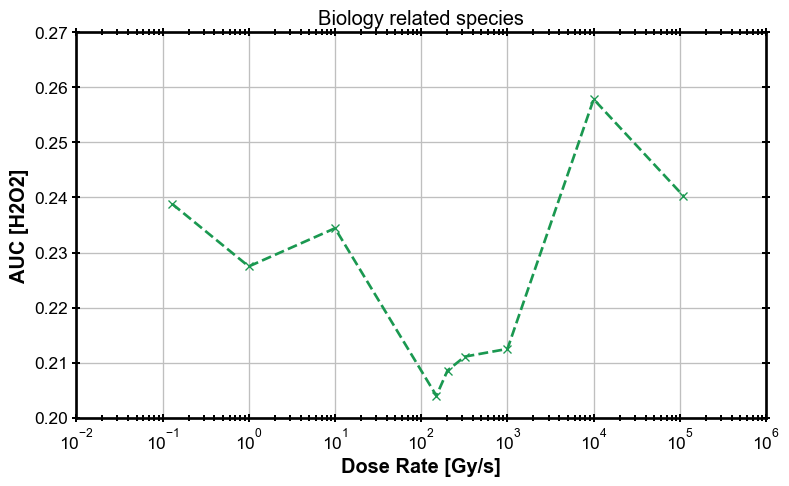

In [61]:
species = "H2O2"
adf = pd.Series(dtype=np.float64)
for adr, df in sims.iter_pandas():
    mask = np.where((df.index>=1e-6))
    adf.loc[adr] = simpson(y=df[species].values[mask].clip(min=0), x=df.index[mask])
    
with fig_man.open(f"Comparison of {species} ROO_r") as (fig, ax):
    
    ax.plot(adf.index, adf, marker="x")

    #ax.set_ylim(bottom=1e-6, top=2)
    #ax.set_ylim([0.5, 1.1])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Dose Rate [Gy/s]")
    ax.set_ylabel("AUC [H2O2]")

    ax.set_title("Biology related species")

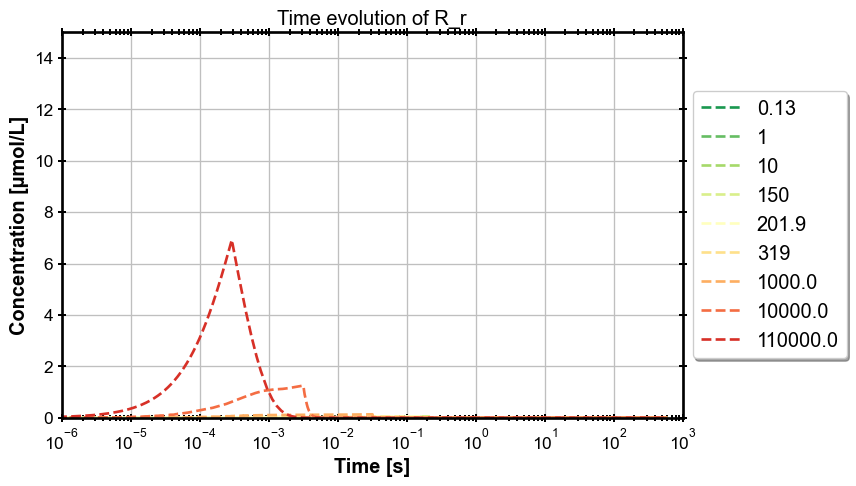

In [63]:
species = "R_r"
title = f"Time evolution of {species}"
with fig_man.open(title) as (fig, ax):
    make_basic_plot(fig, ax, species, sims, title, legend=False, yscale="linear", ylim=[0,15])
    RPlot.set_legend_right(ax)

#### O2

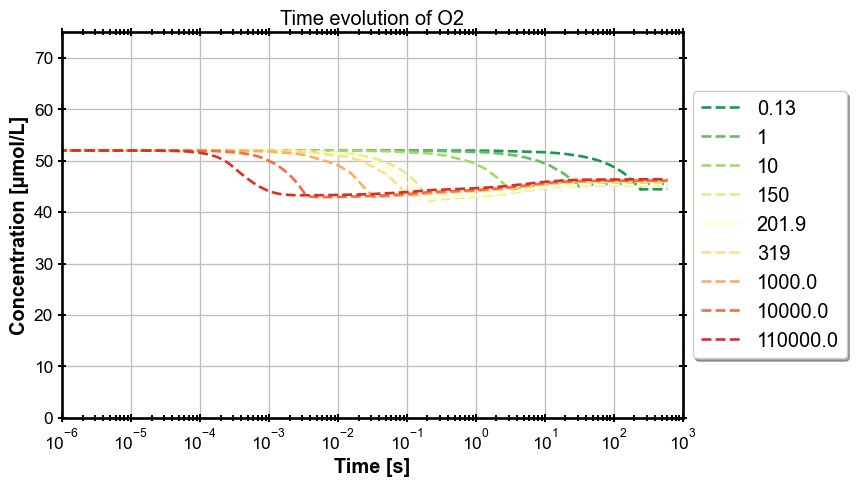

In [65]:
species = "O2"
title = f"Time evolution of {species}"
with fig_man.open(title) as (fig, ax):
    make_basic_plot(fig, ax, species, sims, title, legend=False, yscale="linear", ylim=[0,75])
    RPlot.set_legend_right(ax)

## Oxygen concentration evolution

In [73]:
file = Path(rf"configuration_ELBE.toml")
uc = rp.UnitCell.from_toml(file)

2023-07-31 11:11:09,890::radiopyo::INFO::Loading config from file: configuration_ELBE.toml
2023-07-31 11:11:09,898::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\config_Labarbe.toml
2023-07-31 11:11:09,904::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\basic_water_radiolysis.toml
2023-07-31 11:11:10,077::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\reactions_biology.toml
2023-07-31 11:11:10,117::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2023-07-31 11:11:10,351::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2023-07-31 11:11:10,545::radiopyo::INFO::File is loaded
2023-07-31 11:11:10,545::radiopyo::INFO::Beam configuration detected in config file
2023-07-31 11:11:10,546::radiopyo::INFO::BEAM:: Assigning 'default' name to beam definition constant -> {'dose_rate': 0.13, 'max_dose': 32, 's

In [74]:
uc.set_beam("O2_depletion")

2023-07-31 11:11:13,613::radiopyo::INFO::Setting new beam definition (O2_depletion): PulsedBeam(dose_rate=4083.3333333333335, timer=Timer(period=120, on_time=0.1, start_time=30), max_dose=490000.0, label='default', time_at_max_dose=30.1, dose_per_pulse=490000.0, peak_dose_rate=4900000.0), done!
2023-07-31 11:11:13,614::radiopyo::INFO::Adapting (from Boscolo) Radiolytic yields to 0.27 keV/µm


In [75]:
uc.beam_list.current

PulsedBeam(dose_rate=4083.3333333333335, timer=Timer(period=120, on_time=0.1, start_time=30), max_dose=490000.0, label='default', time_at_max_dose=30.1, dose_per_pulse=490000.0, peak_dose_rate=4900000.0)

In [76]:
sim = uc.prepare_chunked_run([1e-9, 1000], atol=1e-7, rtol=1e-5, use_jac=False)
res = sim.run()
df = res.to_pandas()



2023-07-31 11:11:16,693::radiopyo::INFO::Simulation divided in 3 chunks
2023-07-31 11:11:16,696::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/3 [00:00<?, ?it/s]

2023-07-31 11:11:17,576::radiopyo::INFO::Simulation done!


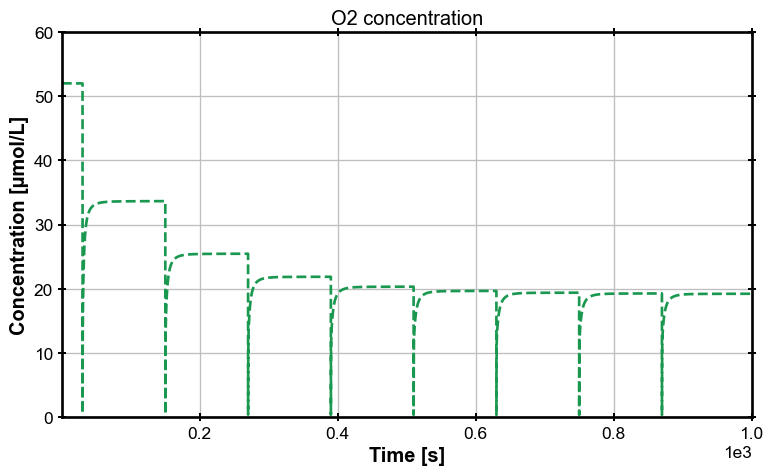

In [69]:
species = "O2"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    ax.plot(df.index, df[species], marker="")

    ax.set_ylim(bottom=0, top=60)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("O2 concentration")

In [46]:
150e-6 * 769.23 * 760

87.69221999999999

In [63]:
0.04/769.23

5.2000052000052e-05